<a href="https://colab.research.google.com/github/MaanyaGupta/CSET343/blob/main/CSET343_lab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q wfdb pydicom nltk scikit-learn seaborn pillow

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import wfdb
from wfdb import processing

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report, roc_curve)

import warnings
warnings.filterwarnings("ignore")

In [ ]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

cols = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
        "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"]

# In this file, missing values are marked with '?'
df = pd.read_csv(url, names=cols, na_values="?")
print("Shape:", df.shape)
df.head()

Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [ ]:
print("=== Data types ===")
print(df.dtypes, "\n")

print("=== Missing values ===")
print(df.isnull().sum(), "\n")

print("=== Summary statistics ===")
df.describe().T

=== Data types ===
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object 

=== Missing values ===
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64 

=== Summary statistics ===


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


In [ ]:
# Missing values are only in 'ca' and 'thal' (both categorical) -> fill with mode
for c in ["ca", "thal"]:
    df[c] = df[c].fillna(df[c].mode()[0])

# Original target: 0 = no disease, 1-4 = disease  -> binary 0 vs 1+
print("Original target distribution:\n", df["target"].value_counts().sort_index(), "\n")
df["target"] = (df["target"] > 0).astype(int)
print("Binary target distribution:\n", df["target"].value_counts())

# Categorical vs numerical features
categorical = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
numerical   = ["age", "trestbps", "chol", "thalach", "oldpeak"]

# Simple validation of ranges
assert df["age"].between(0, 120).all()
assert df["trestbps"].between(50, 250).all()
print("\nValidation passed. Missing values left:", df.isnull().sum().sum())

Original target distribution:
 target
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64 

Binary target distribution:
 target
0    164
1    139
Name: count, dtype: int64

Validation passed. Missing values left: 0


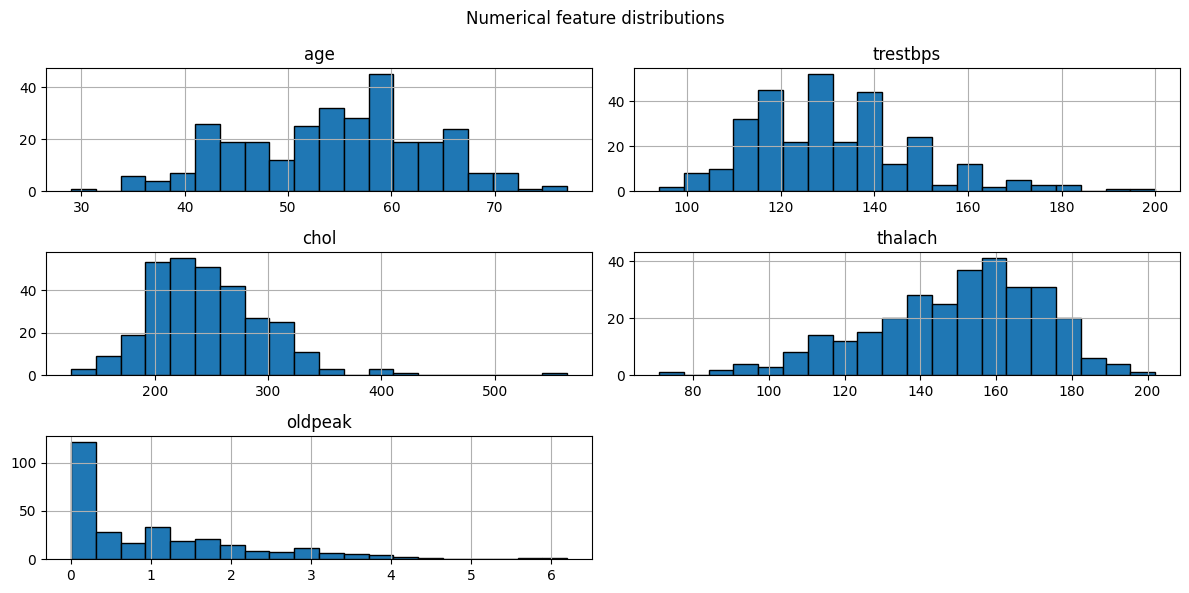

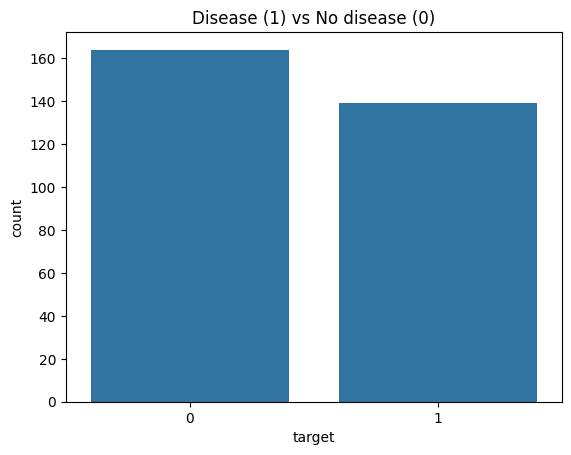

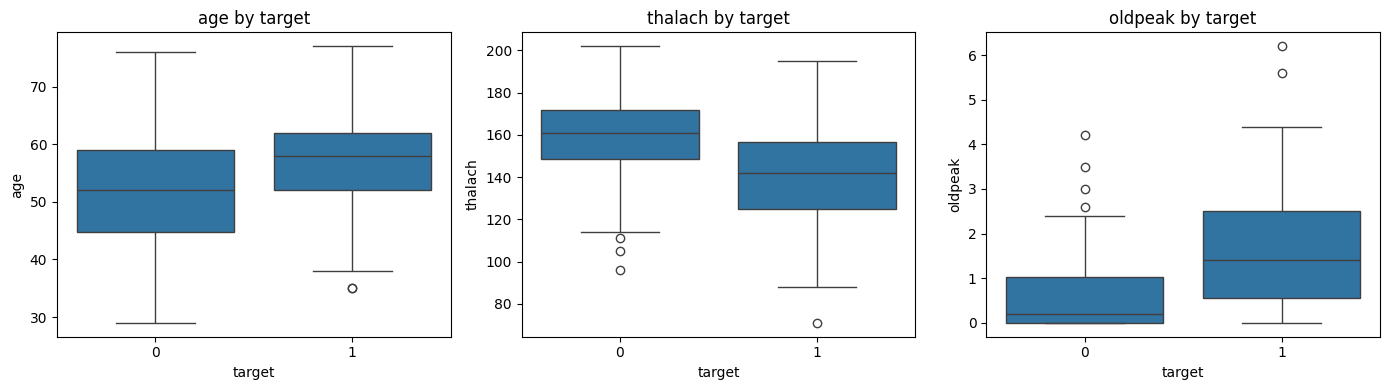

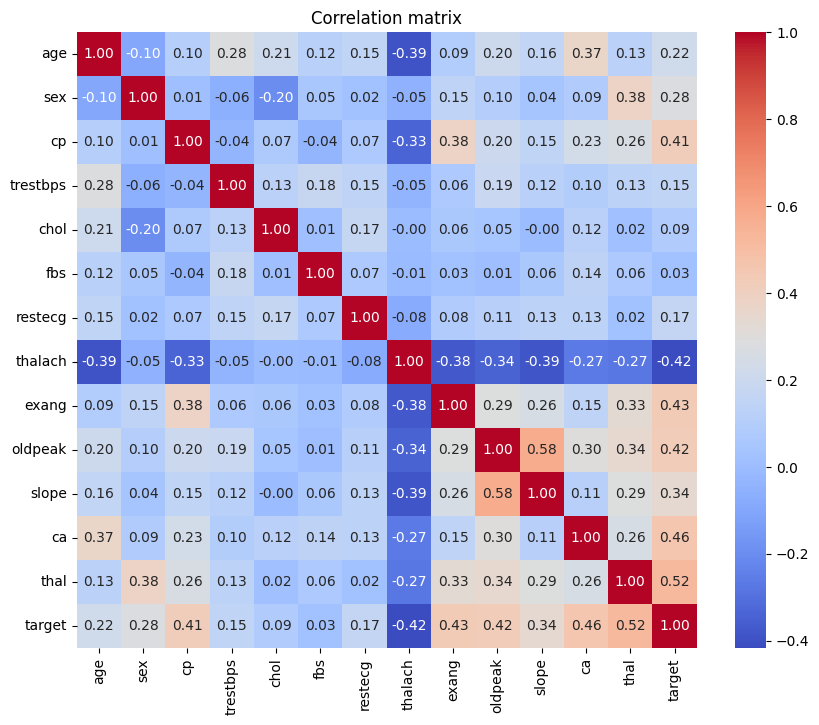

In [ ]:
# Distributions of numerical features
df[numerical].hist(bins=20, figsize=(12, 6), edgecolor="black")
plt.suptitle("Numerical feature distributions")
plt.tight_layout(); plt.show()

# Class balance
sns.countplot(x="target", data=df)
plt.title("Disease (1) vs No disease (0)"); plt.show()

# Numerical features by target
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["age", "thalach", "oldpeak"]):
    sns.boxplot(x="target", y=col, data=df, ax=ax)
    ax.set_title(f"{col} by target")
plt.tight_layout(); plt.show()

# Correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation matrix"); plt.show()

In [ ]:
X = pd.get_dummies(df.drop(columns="target"), columns=categorical, drop_first=True)
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

clf = LogisticRegression(max_iter=1000)
clf.fit(X_train_s, y_train)

y_pred = clf.predict(X_test_s)
y_prob = clf.predict_proba(X_test_s)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("ROC AUC :", round(roc_auc_score(y_test, y_prob), 4))
print("\n", classification_report(y_test, y_pred, target_names=["No disease", "Disease"]))

Accuracy: 0.8525
ROC AUC : 0.9513

               precision    recall  f1-score   support

  No disease       0.88      0.85      0.86        33
     Disease       0.83      0.86      0.84        28

    accuracy                           0.85        61
   macro avg       0.85      0.85      0.85        61
weighted avg       0.85      0.85      0.85        61



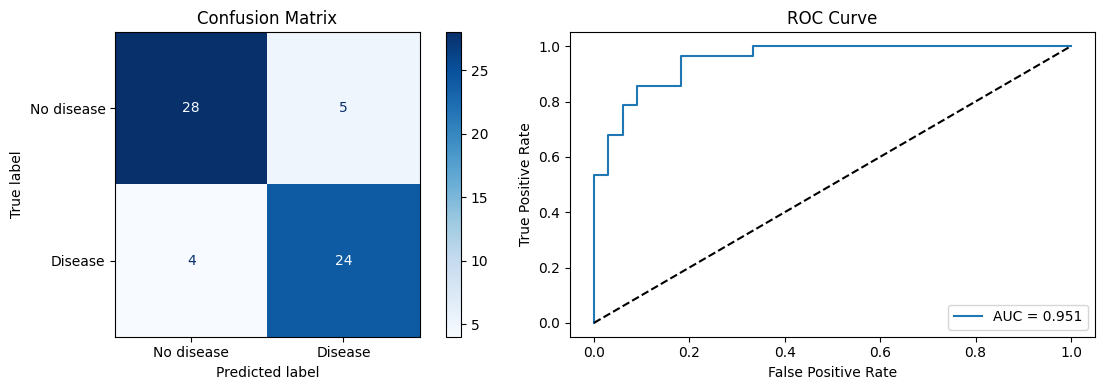

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["No disease", "Disease"]).plot(ax=axes[0], cmap="Blues")
axes[0].set_title("Confusion Matrix")

fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, y_prob):.3f}")
axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC Curve"); axes[1].legend()
plt.tight_layout(); plt.show()

Part B: Signal data


In [ ]:
# Streams record '100' directly from PhysioNet (no manual download)
record = wfdb.rdrecord("100", pn_dir="mitdb")
ann    = wfdb.rdann("100", "atr", pn_dir="mitdb")

fs = record.fs
print("Sampling rate (Hz):", fs)
print("Signal shape      :", record.p_signal.shape)
print("Channels          :", record.sig_name)
print("Duration (sec)    :", record.sig_len / fs)
print("Units             :", record.units)
print("Number of annotations:", len(ann.sample))
print("Beat symbols found:", set(ann.symbol))

Sampling rate (Hz): 360
Signal shape      : (650000, 2)
Channels          : ['MLII', 'V5']
Duration (sec)    : 1805.5555555555557
Units             : ['mV', 'mV']
Number of annotations: 2274
Beat symbols found: {'A', '+', 'V', 'N'}


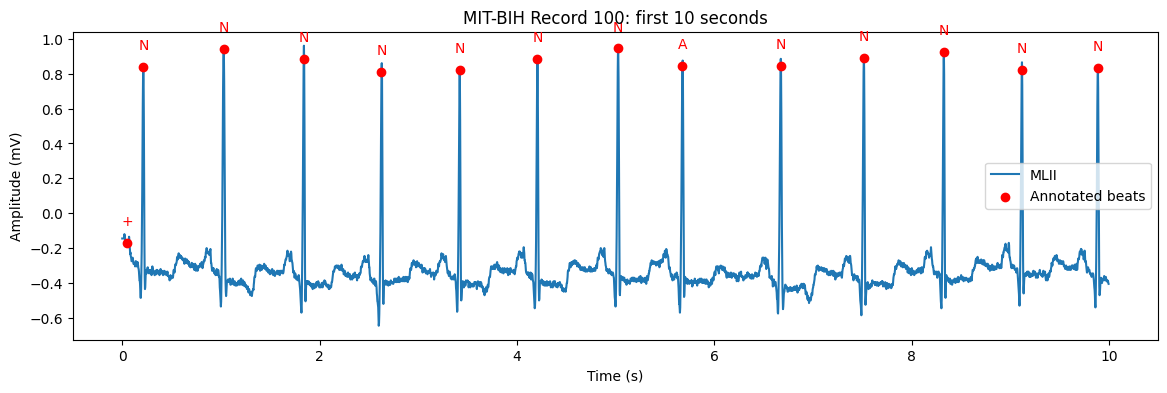

In [ ]:
start, end = 0, 10 * fs        # first 10 seconds
sig = record.p_signal[start:end, 0]
t   = np.arange(start, end) / fs

# annotations that fall inside this window
mask = (ann.sample >= start) & (ann.sample < end)
ann_idx = ann.sample[mask]
ann_sym = np.array(ann.symbol)[mask]

plt.figure(figsize=(14, 4))
plt.plot(t, sig, label=record.sig_name[0])
plt.scatter(ann_idx / fs, record.p_signal[ann_idx, 0], color="red", zorder=3, label="Annotated beats")
for i, s in zip(ann_idx, ann_sym):
    plt.text(i / fs, record.p_signal[i, 0] + 0.1, s, color="red", ha="center")
plt.xlabel("Time (s)"); plt.ylabel("Amplitude (mV)")
plt.title("MIT-BIH Record 100: first 10 seconds")
plt.legend(); plt.show()

Total beats      : 2273
Mean RR (ms)     : 794.6
Mean HR (bpm)    : 75.8
SDNN (ms)        : 48.8
RMSSD (ms)       : 63.2
pNN50 (%)        : 10.00


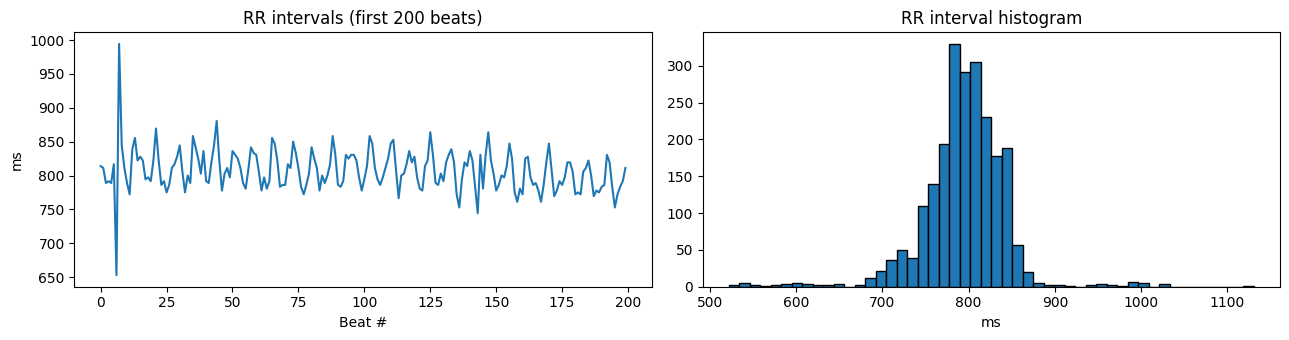

,count
N,2239
A,33
V,1


In [ ]:
# Use only actual beat annotations (exclude rhythm/non-beat labels)
beat_symbols = set("NLRBAaJSVrFejnE/fQ?")
beat_mask = np.array([s in beat_symbols for s in ann.symbol])
beat_samples = ann.sample[beat_mask]

rr = np.diff(beat_samples) / fs * 1000          # RR intervals in ms
hr = 60000 / rr                                 # instantaneous heart rate (bpm)

sdnn  = np.std(rr)
rmssd = np.sqrt(np.mean(np.diff(rr) ** 2))
pnn50 = np.mean(np.abs(np.diff(rr)) > 50) * 100

print(f"Total beats      : {len(beat_samples)}")
print(f"Mean RR (ms)     : {rr.mean():.1f}")
print(f"Mean HR (bpm)    : {hr.mean():.1f}")
print(f"SDNN (ms)        : {sdnn:.1f}")
print(f"RMSSD (ms)       : {rmssd:.1f}")
print(f"pNN50 (%)        : {pnn50:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].plot(rr[:200]); axes[0].set_title("RR intervals (first 200 beats)")
axes[0].set_xlabel("Beat #"); axes[0].set_ylabel("ms")
axes[1].hist(rr, bins=50, edgecolor="black"); axes[1].set_title("RR interval histogram")
axes[1].set_xlabel("ms")
plt.tight_layout(); plt.show()

# Beat type counts
pd.Series(np.array(ann.symbol)[beat_mask]).value_counts().rename("count").to_frame()

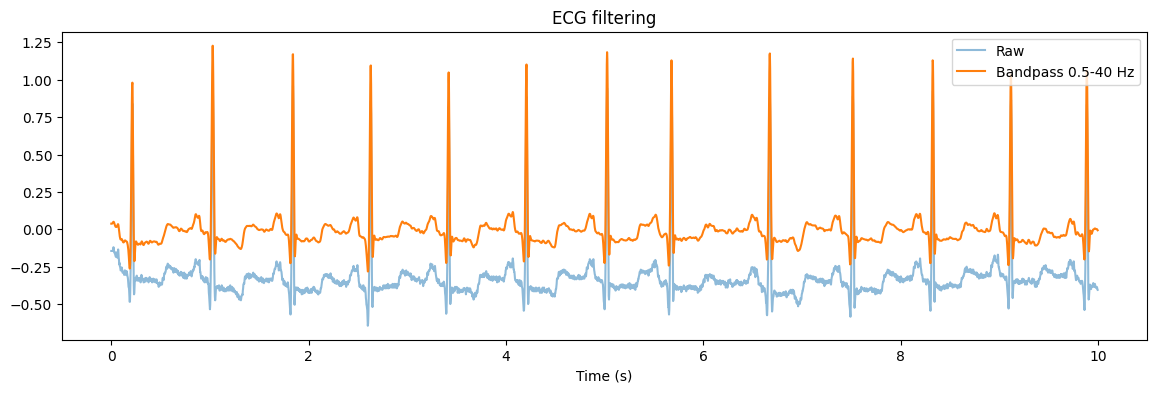

In [ ]:
from scipy.signal import butter, filtfilt

def bandpass(x, low=0.5, high=40, fs=360, order=3):
    b, a = butter(order, [low / (fs / 2), high / (fs / 2)], btype="band")
    return filtfilt(b, a, x)

filtered = bandpass(sig, fs=fs)

plt.figure(figsize=(14, 4))
plt.plot(t, sig, alpha=0.5, label="Raw")
plt.plot(t, filtered, label="Bandpass 0.5-40 Hz")
plt.legend(); plt.title("ECG filtering"); plt.xlabel("Time (s)"); plt.show()

Total tokens   : 100
After cleaning : 47
Top 15 words   : [('patient', 2), ('date', 2), ('pain', 2), ('redacted', 1), ('male', 1), ('presents', 1), ('chest', 1), ('radiating', 1), ('left', 1), ('arm', 1), ('past', 1), ('two', 1), ('hours', 1), ('described', 1), ('severity', 1)]

Symptom keywords found: ['breath', 'chest', 'pain', 'radiating', 'sweating']


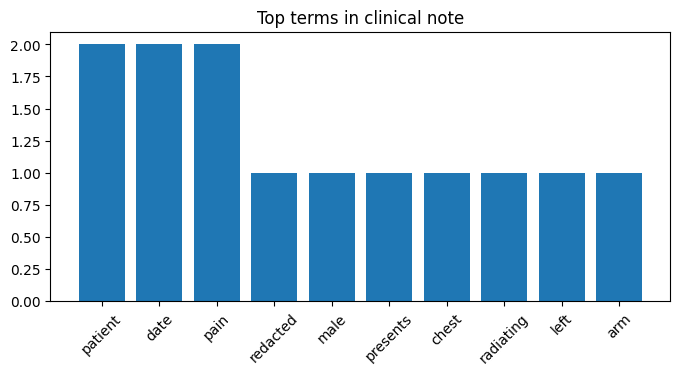

In [ ]:
import re, nltk
from collections import Counter
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

note = """
Patient ID: P-1043. Date: 2024-03-12.
58-year-old male presents with chest pain radiating to the left arm for the past two hours.
Pain is described as pressure-like, 7/10 severity, associated with shortness of breath and sweating.
History of hypertension and high cholesterol. Patient is a former smoker.
Vitals: BP 150/95 mmHg, heart rate 102 bpm, SpO2 96%.
ECG shows ST depression in leads V4-V6. Troponin ordered. Started on aspirin and nitroglycerin.
Plan: admit for observation and cardiology consult.
"""

# Save as a plain .txt file, then read it back (demonstrates file reading)
with open("patient_note.txt", "w") as f:
    f.write(note)
with open("patient_note.txt") as f:
    text = f.read()

# Simple de-identification
clean = re.sub(r"Patient ID:\s*\S+", "Patient ID: [REDACTED]", text)
clean = re.sub(r"\d{4}-\d{2}-\d{2}", "[DATE]", clean)

tokens = word_tokenize(clean.lower())
stop = set(stopwords.words("english"))
words = [w for w in tokens if w.isalpha() and w not in stop and len(w) > 2]

freq = Counter(words)
print("Total tokens   :", len(tokens))
print("After cleaning :", len(words))
print("Top 15 words   :", freq.most_common(15))

# Keyword extraction using a small clinical vocabulary
symptoms = {"chest", "pain", "breath", "sweating", "pressure", "radiating"}
found = sorted(symptoms & set(words))
print("\nSymptom keywords found:", found)

# Plot
top = freq.most_common(10)
plt.figure(figsize=(8, 3.5))
plt.bar([w for w, _ in top], [c for _, c in top])
plt.xticks(rotation=45); plt.title("Top terms in clinical note"); plt.show()

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

docs = [
    clean,
    "Patient reports mild headache and nausea for two days. No fever. Prescribed paracetamol.",
    "Routine follow up for diabetes. Blood sugar controlled. Continue metformin."
]
tfidf = TfidfVectorizer(stop_words="english")
M = tfidf.fit_transform(docs)
terms = np.array(tfidf.get_feature_names_out())
top_idx = M[0].toarray().ravel().argsort()[::-1][:10]
print("Top TF-IDF terms for chest-pain note:", terms[top_idx])

Top TF-IDF terms for chest-pain note: ['date' 'pain' 'patient' 'v6' 'troponin' 'sweating' 'started' 'v4' 'year'
 'vitals']


Format: PNG | Mode: L | Size: (512, 512)
Array shape: (224, 224) | min/max: 0.078431375 0.78431374


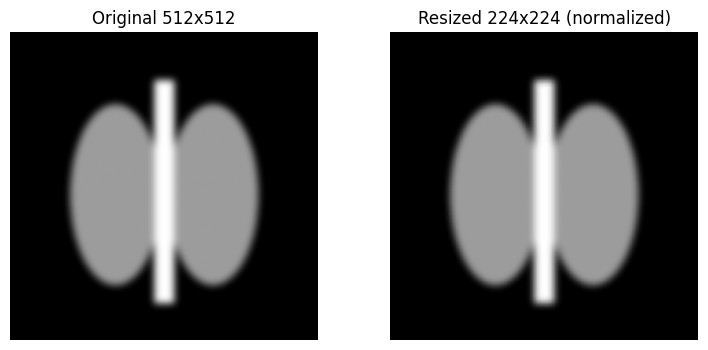

In [ ]:
from PIL import Image, ImageDraw, ImageFilter

# Synthetic "X-ray-like" grayscale image (swap with a real CC0 chest X-ray if you wish)
img = Image.new("L", (512, 512), color=20)
d = ImageDraw.Draw(img)
d.ellipse([100, 120, 250, 420], fill=130)    # left lung
d.ellipse([262, 120, 412, 420], fill=130)    # right lung
d.rectangle([240, 80, 272, 450], fill=200)   # spine/mediastinum
img = img.filter(ImageFilter.GaussianBlur(6))
img.save("sample_xray.png")

# Load back
loaded = Image.open("sample_xray.png")
print("Format:", loaded.format, "| Mode:", loaded.mode, "| Size:", loaded.size)

resized = loaded.resize((224, 224))
arr = np.array(resized).astype("float32") / 255.0     # normalize 0-1
print("Array shape:", arr.shape, "| min/max:", arr.min(), arr.max())

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(loaded, cmap="gray"); axes[0].set_title("Original 512x512")
axes[1].imshow(arr, cmap="gray");    axes[1].set_title("Resized 224x224 (normalized)")
for a in axes: a.axis("off")
plt.show()

Modality        : CT
Patient Name    : CompressedSamples^CT1
Patient ID      : 1CT1
Rows x Columns  : 128 x 128
Bits Allocated  : 16
Study Date      : 20040119
Pixel array shape: (128, 128) | dtype: int16


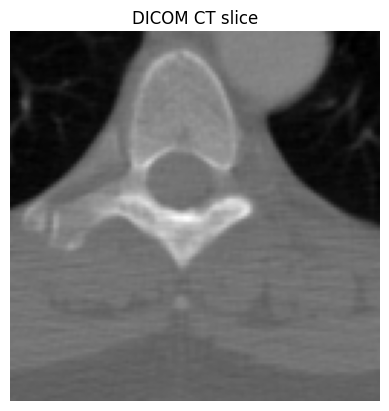

In [ ]:
import pydicom
from pydicom.data import get_testdata_file

dcm_path = get_testdata_file("CT_small.dcm")     # sample DICOM bundled with pydicom
ds = pydicom.dcmread(dcm_path)

print("Modality        :", ds.Modality)
print("Patient Name    :", ds.PatientName)
print("Patient ID      :", ds.PatientID)
print("Rows x Columns  :", ds.Rows, "x", ds.Columns)
print("Bits Allocated  :", ds.BitsAllocated)
print("Study Date      :", ds.get("StudyDate", "N/A"))

pix = ds.pixel_array
print("Pixel array shape:", pix.shape, "| dtype:", pix.dtype)

# Simple min-max normalization / windowing
pix_norm = (pix - pix.min()) / (pix.max() - pix.min())
plt.imshow(pix_norm, cmap="gray"); plt.title("DICOM CT slice"); plt.axis("off"); plt.show()

In [ ]:
import os, json, hashlib, datetime

def checksum(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

def load_any(path):
    ext = os.path.splitext(path)[1].lower()
    if ext in [".csv", ".tsv"]:
        return "tabular", pd.read_csv(path, sep=None, engine="python")
    if ext in [".xlsx", ".xls"]:
        return "tabular", pd.read_excel(path)
    if ext == ".json":
        return "tabular", pd.read_json(path)
    if ext == ".txt":
        return "text", open(path).read()
    if ext in [".png", ".jpg", ".jpeg"]:
        return "image", np.array(Image.open(path))
    if ext == ".dcm":
        return "image", pydicom.dcmread(path).pixel_array
    raise ValueError(f"Unsupported format: {ext}")

def inspect(modality, obj):
    if modality == "tabular":
        return {"shape": obj.shape, "missing": int(obj.isnull().sum().sum())}
    if modality == "text":
        return {"chars": len(obj), "words": len(obj.split())}
    if modality == "image":
        return {"shape": obj.shape, "dtype": str(obj.dtype), "min": float(obj.min()), "max": float(obj.max())}

# Save heart data so it can be ingested as a file
df.to_csv("heart_clean.csv", index=False)

files = ["heart_clean.csv", "patient_note.txt", "sample_xray.png", dcm_path]
manifest, dataset = [], {}

for f in files:
    mod, obj = load_any(f)
    dataset[os.path.basename(f)] = obj
    manifest.append({
        "file": os.path.basename(f),
        "modality": mod,
        "summary": inspect(mod, obj),
        "md5": checksum(f),
        "loaded_at": datetime.datetime.now().isoformat(timespec="seconds")
    })

# Signal data (WFDB) added separately
manifest.append({"file": "mitdb/100", "modality": "signal",
                 "summary": {"fs": fs, "channels": record.sig_name, "length": record.sig_len}})

with open("manifest.json", "w") as f:
    json.dump(manifest, f, indent=2, default=str)

print(json.dumps(manifest, indent=2, default=str))

[
  {
    "file": "heart_clean.csv",
    "modality": "tabular",
    "summary": {
      "shape": [
        303,
        14
      ],
      "missing": 0
    },
    "md5": "34e0685f5207b04157df0dd11e3e64fe",
    "loaded_at": "2026-10-21T14:34:41"
  },
  {
    "file": "patient_note.txt",
    "modality": "text",
    "summary": {
      "chars": 508,
      "words": 77
    },
    "md5": "7d9d992331834de54ca847cd6fda3364",
    "loaded_at": "2026-10-21T14:34:41"
  },
  {
    "file": "sample_xray.png",
    "modality": "image",
    "summary": {
      "shape": [
        512,
        512
      ],
      "dtype": "uint8",
      "min": 20.0,
      "max": 200.0
    },
    "md5": "67fa44fcc8d80f05d1f3b06f065841da",
    "loaded_at": "2026-10-21T14:34:41"
  },
  {
    "file": "CT_small.dcm",
    "modality": "image",
    "summary": {
      "shape": [
        128,
        128
      ],
      "dtype": "int16",
      "min": 128.0,
      "max": 2191.0
    },
    "md5": "ccf71ca6735bc1c52fbe33e29eb42886",
    "loa